In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Library

In [ ]:
# 데이터 전처리
import pandas as pd
import numpy as np
from tqdm import tqdm
tqdm.pandas()
import gzip
import json

# 데이터 시각화 (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# 텍스트 데이터 전처리 (nltk)
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [ ]:
# nltk download
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

# Utils

In [ ]:
# 데이터 불러오기
def parse(path):
  g = gzip.open(path, 'rb')
  for l in g:
    yield json.loads(l)

def getDF(path):
  i = 0
  df = {}
  for d in parse(path):
    df[i] = d
    i += 1
  return pd.DataFrame.from_dict(df, orient='index')

In [ ]:
# Top 5 core Filtering
def top_n_filtering(data, chk=5):
    cnt = 1
    while True:
        # 사용자 필터링
        user_counts = data['user_id'].value_counts()
        users_to_remove = user_counts[user_counts < chk].index
        data = data[~data['user_id'].isin(users_to_remove)]

        # 아이템 필터링
        item_counts = data['asin'].value_counts()
        items_to_remove = item_counts[item_counts < chk].index
        data = data[~data['asin'].isin(items_to_remove)]

        print(f"Epoch {cnt}")
        print(f" - Remaining users: {data['user_id'].nunique()}")
        print(f" - Remaining items: {data['asin'].nunique()}")
        print(f" - Remaining reviews: {len(data)}")

        # 두 조건 모두 만족 시 종료
        if (len(users_to_remove) == 0) and (len(items_to_remove) == 0):
            break

        cnt += 1

    return data

In [ ]:
# 사용자별 Top-N 필터링
def user_top_n_filtering(data, chk=5):
    cnt = 1
    while True:
        # 사용자별 리뷰 수 카운트
        user_counts = data['user_id'].value_counts()
        users_to_remove = user_counts[user_counts < chk].index
        if len(users_to_remove) == 0:
            break

        data = data[~data['user_id'].isin(users_to_remove)]

        print(f"Epoch {cnt}")
        print(f" - Remaining users: {data['user_id'].nunique()}")
        print(f" - Remaining items: {data['asin'].nunique()}")
        print(f" - Remaining reviews: {len(data)}")

        cnt += 1
    return data

# Load Dataset

In [ ]:
# 리뷰 데이터셋 확인
df = getDF('/content/drive/MyDrive/Dataset/Amazon_Dataset/Review/Cell_Phones_and_Accessories.jsonl.gz')

print(df.shape)
df.head()

(20812945, 10)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4.0,No white background! It’s clear!,I bought this bc I thought it had the nice whi...,[{'small_image_url': 'https://images-na.ssl-im...,B08L6L3X1S,B08L6L3X1S,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1612044451196,0,True
1,5.0,Awesome! Great price! Works well!,Perfect. How pissed am I that I recently paid ...,[],B079BPGF6C,B079BPGF6C,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1534443517349,2,True
2,5.0,Worked but took an hour to install,Overall very happy with the end result. If you...,[{'small_image_url': 'https://m.media-amazon.c...,B088DR7Z5B,B0BBGGC8F2,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1629235304798,3,True
3,4.0,Decent,Lasted about 9 months then the lock button bro...,[{'small_image_url': 'https://images-na.ssl-im...,B07XRDHDNQ,B07XRDHDNQ,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1590470082910,0,True
4,5.0,LOVE IT!,LOVE THIS CASE! Works better than my expensive...,[],B00A8ZDL9Y,B00A8ZDL9Y,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1408994588000,0,True


In [ ]:
# 아이템 메타 데이터셋 확인
meta_df = getDF('/content/drive/MyDrive/Dataset/Amazon_Dataset/Meta/meta_Cell_Phones_and_Accessories.jsonl.gz')

print(meta_df.shape)
meta_df.head()

(1288490, 16)


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
0,Cell Phones & Accessories,ARAREE Slim Diary Cell Phone Case for Samsung ...,3.8,5,"[Genuine Cow leather with 6 different colors, ...","[JUST LOOK, You can tell the difference. Make ...",None,[{'thumb': 'https://m.media-amazon.com/images/...,[],araree,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '3.35 x 0.59 x 6.18 inc...,B013SK1JTY,None,NaN,NaN
1,Cell Phones & Accessories,Bastmei for OnePlus 7T Case Extremely Light Ul...,4.4,177,[Ultra-thin & Ultra-light: The ultra slim fit ...,[],11.98,[{'thumb': 'https://m.media-amazon.com/images/...,[],Bastmei,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Package Dimensions': '7.6 x 4.29 x 0.75 inch...,B07ZPSG8P5,None,NaN,NaN
2,Cell Phones & Accessories,Wireless Fones Branded New Iphone 5C/LITE Hot ...,4.0,2,[],[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[],WIRELESS FONES,"[Cell Phones & Accessories, iPhone Accessories]","{'Item model number': 'Apple Iphone 5C', 'Othe...",B00GKR3L12,None,NaN,NaN
3,Cell Phones & Accessories,"iPhone 6 Plus + Case, DandyCase Perfect PATTER...",4.0,15,"[Slim-Fit design for the iPhone 6 Plus (5.5"" s...",[Case does not need to be removed for charging...,None,[{'thumb': 'https://m.media-amazon.com/images/...,[],DandyCase,"[Cell Phones & Accessories, iPhone Accessories]",{'Product Dimensions': '5.43 x 0.28 x 2.64 inc...,B00PB8U8BW,None,NaN,NaN
4,Cell Phones & Accessories,"Case for Galaxy S6/S6 Edge, Thin Translucent V...",4.0,1,[],[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[],7Pite,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Package Dimensions': '8.31 x 3.74 x 0.55 inc...,B07D3RHSRV,None,NaN,NaN


In [ ]:
# 공통으로 존재하는 parent_asin Column으로 결합.
merged = df.merge(meta_df, on='parent_asin', how='left')

print(merged.shape)
merged.head()

(20812945, 25)


,rating,title_x,text,images_x,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,...,description,price,images_y,videos,store,categories,details,bought_together,subtitle,author
0,4.0,No white background! It’s clear!,I bought this bc I thought it had the nice whi...,[{'small_image_url': 'https://images-na.ssl-im...,B08L6L3X1S,B08L6L3X1S,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1612044451196,0,True,...,[VUIIMEEK Glitter Crystal Clear Case for iPhon...,None,[{'thumb': 'https://m.media-amazon.com/images/...,[],VUIIMEEK,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '3.54 x 6.3 x 0.39 inch...,None,NaN,NaN
1,5.0,Awesome! Great price! Works well!,Perfect. How pissed am I that I recently paid ...,[],B079BPGF6C,B079BPGF6C,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1534443517349,2,True,...,[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[],Fitian,"[Cell Phones & Accessories, Accessories, Smart...",{'Package Dimensions': '4.5 x 2.4 x 0.4 inches...,None,NaN,NaN
2,5.0,Worked but took an hour to install,Overall very happy with the end result. If you...,[{'small_image_url': 'https://m.media-amazon.c...,B088DR7Z5B,B0BBGGC8F2,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1629235304798,3,True,...,[],23.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'ZTR iPhone XR replace Screen Insta...,Keytas,"[Cell Phones & Accessories, Accessories, Maint...",{'Package Dimensions': '7.91 x 6.77 x 0.71 inc...,None,NaN,NaN
3,4.0,Decent,Lasted about 9 months then the lock button bro...,[{'small_image_url': 'https://images-na.ssl-im...,B07XRDHDNQ,B07XRDHDNQ,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1590470082910,0,True,...,[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Torras Slim Fit Plastic Case Revie...,TORRAS,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '6.93 x 3.78 x 0.63 inc...,None,NaN,NaN
4,5.0,LOVE IT!,LOVE THIS CASE! Works better than my expensive...,[],B00A8ZDL9Y,B00A8ZDL9Y,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1408994588000,0,True,...,"[Exclusive design, classic phone case]",None,[{'thumb': 'https://m.media-amazon.com/images/...,[],sourcing map,"[Cell Phones & Accessories, iPhone Accessories]",{'Product Dimensions': '5.61 x 2.97 x 0.36 inc...,None,NaN,NaN


In [ ]:
# 사용자가 남긴 img가 있는 데이터만 분리
merged_img = merged.loc[merged['images_x'].apply(lambda x: len(x) > 0)]
merged_img = merged_img.reset_index(drop=True)

print(merged_img.shape)
merged_img.head()

(1040954, 25)


,rating,title_x,text,images_x,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,...,description,price,images_y,videos,store,categories,details,bought_together,subtitle,author
0,4.0,No white background! It’s clear!,I bought this bc I thought it had the nice whi...,[{'small_image_url': 'https://images-na.ssl-im...,B08L6L3X1S,B08L6L3X1S,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1612044451196,0,True,...,[VUIIMEEK Glitter Crystal Clear Case for iPhon...,None,[{'thumb': 'https://m.media-amazon.com/images/...,[],VUIIMEEK,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '3.54 x 6.3 x 0.39 inch...,None,NaN,NaN
1,5.0,Worked but took an hour to install,Overall very happy with the end result. If you...,[{'small_image_url': 'https://m.media-amazon.c...,B088DR7Z5B,B0BBGGC8F2,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1629235304798,3,True,...,[],23.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'ZTR iPhone XR replace Screen Insta...,Keytas,"[Cell Phones & Accessories, Accessories, Maint...",{'Package Dimensions': '7.91 x 6.77 x 0.71 inc...,None,NaN,NaN
2,4.0,Decent,Lasted about 9 months then the lock button bro...,[{'small_image_url': 'https://images-na.ssl-im...,B07XRDHDNQ,B07XRDHDNQ,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1590470082910,0,True,...,[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Torras Slim Fit Plastic Case Revie...,TORRAS,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '6.93 x 3.78 x 0.63 inc...,None,NaN,NaN
3,5.0,Cute case,Quick shipping! I opened the package and ther...,[{'small_image_url': 'https://images-na.ssl-im...,B08VJ71SFR,B08VHWV56Q,AHREXOGQPZDA6354MHH4ETSF3MCQ,1620104631809,0,True,...,[],13.97,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Wearlizer Bling Protector Case for...,Wearlizer,"[Cell Phones & Accessories, Accessories, Smart...",{'Product Dimensions': '1.7 x 1.4 x 0.4 inches...,None,NaN,NaN
4,2.0,Wouldn’t click closed,Case wouldn’t click closed. If it had this wou...,[{'small_image_url': 'https://images-na.ssl-im...,B07CSLF2P2,B07CSMLTWK,AG35BKPUEUMX7LV5YLOQ5YCQ3GOA,1557761012864,0,True,...,"[Compatible Model:, Samsung Galaxy S9 Galaxy ...",14.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Shields Up Best 3 Cards Holder Cas...,ACXLIFE,"[Cell Phones & Accessories, Cases, Holsters & ...","{'Product Dimensions': '12 x 7 x 0.6 inches', ...",None,NaN,NaN


In [ ]:
# 리뷰 데이터셋 확인
merged_img.to_pickle('/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed/Cell_Phones_and_Accessories_Img_Filtered.pkl')

In [ ]:
merged_img.to_json('/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed/Cell_Phones_and_Accessories_Img_Filtered.json')

# EDA

In [ ]:
# 데이터 수집 기간 확인
date_min = pd.to_datetime(merged_img['timestamp'],unit='ms').min()
date_max = pd.to_datetime(merged_img['timestamp'],unit='ms').max()
date_min,date_max

(Timestamp('2004-12-13 05:10:14'), Timestamp('2023-09-12 13:03:59.340000'))

In [ ]:
# year, month column 생성
merged_img.loc[:, 'year'] = pd.to_datetime(merged_img['timestamp'], unit='ms').dt.year
merged_img.loc[:, 'month'] = pd.to_datetime(merged_img['timestamp'], unit='ms').dt.month

In [ ]:
# 연도별로 축적된 데이터가 얼마나 있는지 확인
merged_img.groupby('year').agg({'rating':'count'}).reset_index().plot(x='year',kind='bar')

<Axes: xlabel='year'>

# Top N Filtering
- review와 image 데이터가 모두 존재하는 데이터를 우선 필터링 하였으므로 Dataset의 Sparsity가 있는 상황임.
- user top 5 filtering을 적용하거나, Top-N filtering을 적용하지 않음.

In [ ]:
# 전체 img_data
merged_img.shape

(1040954, 25)

In [ ]:
# review를 중심으로 중복되는 데이터 삭제
merged_img = merged_img.drop_duplicates(['text'], keep='first')

print(merged_img.shape)
merged_img.head()

(991699, 25)


,rating,title_x,text,images_x,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,...,description,price,images_y,videos,store,categories,details,bought_together,subtitle,author
0,4.0,No white background! It’s clear!,I bought this bc I thought it had the nice whi...,[{'small_image_url': 'https://images-na.ssl-im...,B08L6L3X1S,B08L6L3X1S,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1612044451196,0,True,...,[VUIIMEEK Glitter Crystal Clear Case for iPhon...,None,[{'thumb': 'https://m.media-amazon.com/images/...,[],VUIIMEEK,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '3.54 x 6.3 x 0.39 inch...,None,NaN,NaN
1,5.0,Worked but took an hour to install,Overall very happy with the end result. If you...,[{'small_image_url': 'https://m.media-amazon.c...,B088DR7Z5B,B0BBGGC8F2,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1629235304798,3,True,...,[],23.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'ZTR iPhone XR replace Screen Insta...,Keytas,"[Cell Phones & Accessories, Accessories, Maint...",{'Package Dimensions': '7.91 x 6.77 x 0.71 inc...,None,NaN,NaN
2,4.0,Decent,Lasted about 9 months then the lock button bro...,[{'small_image_url': 'https://images-na.ssl-im...,B07XRDHDNQ,B07XRDHDNQ,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1590470082910,0,True,...,[],None,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Torras Slim Fit Plastic Case Revie...,TORRAS,"[Cell Phones & Accessories, Cases, Holsters & ...",{'Product Dimensions': '6.93 x 3.78 x 0.63 inc...,None,NaN,NaN
3,5.0,Cute case,Quick shipping! I opened the package and ther...,[{'small_image_url': 'https://images-na.ssl-im...,B08VJ71SFR,B08VHWV56Q,AHREXOGQPZDA6354MHH4ETSF3MCQ,1620104631809,0,True,...,[],13.97,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Wearlizer Bling Protector Case for...,Wearlizer,"[Cell Phones & Accessories, Accessories, Smart...",{'Product Dimensions': '1.7 x 1.4 x 0.4 inches...,None,NaN,NaN
4,2.0,Wouldn’t click closed,Case wouldn’t click closed. If it had this wou...,[{'small_image_url': 'https://images-na.ssl-im...,B07CSLF2P2,B07CSMLTWK,AG35BKPUEUMX7LV5YLOQ5YCQ3GOA,1557761012864,0,True,...,"[Compatible Model:, Samsung Galaxy S9 Galaxy ...",14.99,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Shields Up Best 3 Cards Holder Cas...,ACXLIFE,"[Cell Phones & Accessories, Cases, Holsters & ...","{'Product Dimensions': '12 x 7 x 0.6 inches', ...",None,NaN,NaN


In [ ]:
top3 = top_n_filtering(merged_img, 3)

# index 초기화
top3 = top3.reset_index(drop=True)
top3.shape

Epoch 1
 - Remaining users: 23730
 - Remaining items: 12047
 - Remaining reviews: 61368
Epoch 2
 - Remaining users: 7423
 - Remaining items: 6642
 - Remaining reviews: 31932
Epoch 3
 - Remaining users: 5286
 - Remaining items: 5663
 - Remaining reviews: 26910
Epoch 4
 - Remaining users: 4692
 - Remaining items: 5333
 - Remaining reviews: 25277
Epoch 5
 - Remaining users: 4467
 - Remaining items: 5205
 - Remaining reviews: 24643
Epoch 6
 - Remaining users: 4368
 - Remaining items: 5144
 - Remaining reviews: 24338
Epoch 7
 - Remaining users: 4315
 - Remaining items: 5109
 - Remaining reviews: 24169
Epoch 8
 - Remaining users: 4277
 - Remaining items: 5085
 - Remaining reviews: 24047
Epoch 9
 - Remaining users: 4257
 - Remaining items: 5072
 - Remaining reviews: 23982
Epoch 10
 - Remaining users: 4241
 - Remaining items: 5062
 - Remaining reviews: 23930
Epoch 11
 - Remaining users: 4229
 - Remaining items: 5053
 - Remaining reviews: 23888
Epoch 12
 - Remaining users: 4217
 - Remaining ite

(23801, 27)

# Top 3 Image EDA

<Axes: xlabel='year'>

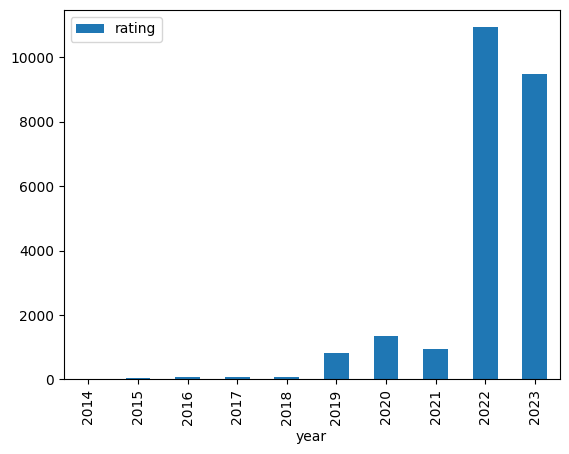

In [ ]:
# 연도별로 축적된 데이터가 얼마나 있는지 확인
top3.groupby('year').agg({'rating':'count'}).reset_index().plot(x='year',kind='bar')

## 2014 image

In [ ]:
for data in top3.loc[top3['year']==2014, 'images_x'].values[:50]:
    print(data[0]['small_image_url'])

https://images-na.ssl-images-amazon.com/images/I/41KpbpnLPML._SL256_.jpg


In [ ]:
for data in top3.loc[top3['year']==2014, 'images_x'].values[:50]:
    print(data[0]['medium_image_url'])

https://images-na.ssl-images-amazon.com/images/I/41KpbpnLPML._SL800_.jpg


In [ ]:
for data in top3.loc[top3['year']==2014, 'images_x'].values[:50]:
    print(data[0]['large_image_url'])

https://images-na.ssl-images-amazon.com/images/I/41KpbpnLPML._SL1600_.jpg


## 2015 image

In [ ]:
for data in top3.loc[top3['year']==2015, 'images_x'].values[:50]:
    print(data[0]['small_image_url'])

https://images-na.ssl-images-amazon.com/images/I/61kat2zaAiL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/717TR9lfNeL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/717Nvjt7lGL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61ybbfqOSDL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71aFpnk07ZL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/710apNVnOUL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/81HcEAAJ8DL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71UOFYNORhL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71AEBjNJn4L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/615vCArbVOL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/712wVgo6QnL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/816N3kC0G6L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/7152rWOBewL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71

In [ ]:
for data in top3.loc[top3['year']==2015, 'images_x'].values[:50]:
    print(data[0]['medium_image_url'])

https://images-na.ssl-images-amazon.com/images/I/61kat2zaAiL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/717TR9lfNeL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/717Nvjt7lGL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61ybbfqOSDL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71aFpnk07ZL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/710apNVnOUL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/81HcEAAJ8DL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71UOFYNORhL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71AEBjNJn4L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/615vCArbVOL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/712wVgo6QnL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/816N3kC0G6L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/7152rWOBewL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71

In [ ]:
for data in top3.loc[top3['year']==2015, 'images_x'].values[:50]:
    print(data[0]['large_image_url'])

https://images-na.ssl-images-amazon.com/images/I/61kat2zaAiL.jpg
https://images-na.ssl-images-amazon.com/images/I/717TR9lfNeL.jpg
https://images-na.ssl-images-amazon.com/images/I/717Nvjt7lGL.jpg
https://images-na.ssl-images-amazon.com/images/I/61ybbfqOSDL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/71aFpnk07ZL.jpg
https://images-na.ssl-images-amazon.com/images/I/710apNVnOUL.jpg
https://images-na.ssl-images-amazon.com/images/I/81HcEAAJ8DL.jpg
https://images-na.ssl-images-amazon.com/images/I/71UOFYNORhL.jpg
https://images-na.ssl-images-amazon.com/images/I/71AEBjNJn4L.jpg
https://images-na.ssl-images-amazon.com/images/I/615vCArbVOL.jpg
https://images-na.ssl-images-amazon.com/images/I/712wVgo6QnL.jpg
https://images-na.ssl-images-amazon.com/images/I/816N3kC0G6L.jpg
https://images-na.ssl-images-amazon.com/images/I/7152rWOBewL.jpg
https://images-na.ssl-images-amazon.com/images/I/715k7OionhL.jpg
https://images-na.ssl-images-amazon.com/images/I/61-A5gPLqyL.jpg
https://images-n

## 2016 image

In [ ]:
for data in top3.loc[top3['year']==2016, 'images_x'].values[:50]:
    print(data[0]['small_image_url'])

https://images-na.ssl-images-amazon.com/images/I/61F4ZDTC-PL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/81iuLubt4QL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/618g8PaSE-L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61D1H+sNc7L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71LRKG7vtcL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71jxrx5ar6L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71QlOLQ0N3L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61S5xIQJpEL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61HZPGvR4nL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71FxoCkW45L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61Y1rhPxTbL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61cC17EV7rL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61cdnq07SEL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71

In [ ]:
for data in top3.loc[top3['year']==2016, 'images_x'].values[:50]:
    print(data[0]['medium_image_url'])

https://images-na.ssl-images-amazon.com/images/I/61F4ZDTC-PL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/81iuLubt4QL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/618g8PaSE-L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61D1H+sNc7L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71LRKG7vtcL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71jxrx5ar6L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71QlOLQ0N3L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61S5xIQJpEL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61HZPGvR4nL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71FxoCkW45L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61Y1rhPxTbL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61cC17EV7rL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61cdnq07SEL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71

In [ ]:
for data in top3.loc[top3['year']==2016, 'images_x'].values[:50]:
    print(data[0]['large_image_url'])

https://images-na.ssl-images-amazon.com/images/I/61F4ZDTC-PL.jpg
https://images-na.ssl-images-amazon.com/images/I/81iuLubt4QL.jpg
https://images-na.ssl-images-amazon.com/images/I/618g8PaSE-L._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/61D1H+sNc7L.jpg
https://images-na.ssl-images-amazon.com/images/I/71LRKG7vtcL.jpg
https://images-na.ssl-images-amazon.com/images/I/71jxrx5ar6L.jpg
https://images-na.ssl-images-amazon.com/images/I/71QlOLQ0N3L.jpg
https://images-na.ssl-images-amazon.com/images/I/61S5xIQJpEL.jpg
https://images-na.ssl-images-amazon.com/images/I/61HZPGvR4nL.jpg
https://images-na.ssl-images-amazon.com/images/I/71FxoCkW45L.jpg
https://images-na.ssl-images-amazon.com/images/I/61Y1rhPxTbL.jpg
https://images-na.ssl-images-amazon.com/images/I/61cC17EV7rL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/61cdnq07SEL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/719G2aZK0gL.jpg
https://images-na.ssl-images-amazon.com/images/I/71C9TFHvzGL._S

## 2017 image

In [ ]:
for data in top3.loc[top3['year']==2017, 'images_x'].values[:50]:
    print(data[0]['small_image_url'])

https://images-na.ssl-images-amazon.com/images/I/41jYtsDEWIL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71N3XhwS8OL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61zX7zScwmL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/610132BqxML._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61WNlN2qcsL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61WNlN2qcsL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61+tsubohkL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71aU5FmA2DL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/618rp7qxwBL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/717VOyC8hPL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71mAsPjXgjL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/714iSqyPFXL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/81iZNJNzfPL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71

In [ ]:
for data in top3.loc[top3['year']==2017, 'images_x'].values[:50]:
    print(data[0]['medium_image_url'])

https://images-na.ssl-images-amazon.com/images/I/41jYtsDEWIL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71N3XhwS8OL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61zX7zScwmL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/610132BqxML._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61WNlN2qcsL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61WNlN2qcsL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61+tsubohkL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71aU5FmA2DL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/618rp7qxwBL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/717VOyC8hPL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71mAsPjXgjL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/714iSqyPFXL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/81iZNJNzfPL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71

In [ ]:
for data in top3.loc[top3['year']==2017, 'images_x'].values[:50]:
    print(data[0]['large_image_url'])

https://images-na.ssl-images-amazon.com/images/I/41jYtsDEWIL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/71N3XhwS8OL.jpg
https://images-na.ssl-images-amazon.com/images/I/61zX7zScwmL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/610132BqxML._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/61WNlN2qcsL.jpg
https://images-na.ssl-images-amazon.com/images/I/61WNlN2qcsL.jpg
https://images-na.ssl-images-amazon.com/images/I/61+tsubohkL.jpg
https://images-na.ssl-images-amazon.com/images/I/71aU5FmA2DL.jpg
https://images-na.ssl-images-amazon.com/images/I/618rp7qxwBL.jpg
https://images-na.ssl-images-amazon.com/images/I/717VOyC8hPL.jpg
https://images-na.ssl-images-amazon.com/images/I/71mAsPjXgjL.jpg
https://images-na.ssl-images-amazon.com/images/I/714iSqyPFXL.jpg
https://images-na.ssl-images-amazon.com/images/I/81iZNJNzfPL.jpg
https://images-na.ssl-images-amazon.com/images/I/71AwCAtY-TL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/61mBx

## 2018 image

In [ ]:
for data in top3.loc[top3['year']==2018, 'images_x'].values[:50]:
    print(data[0]['small_image_url'])

https://images-na.ssl-images-amazon.com/images/I/7192fczB93L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/6119gBwTdoL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61pSRuK9iHL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/514yZfsuLjL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71BeVwB-rHL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/711kR7LIg2L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/81ZC7F+FpaL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71jTuvqobhL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71JX8LCH6LL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71WpFAAYiML._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61TKoc27V-L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61aLTIqmJ7L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/51X5gTvgqtL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61

In [ ]:
for data in top3.loc[top3['year']==2018, 'images_x'].values[:50]:
    print(data[0]['medium_image_url'])

https://images-na.ssl-images-amazon.com/images/I/7192fczB93L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/6119gBwTdoL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61pSRuK9iHL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/514yZfsuLjL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71BeVwB-rHL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/711kR7LIg2L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/81ZC7F+FpaL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71jTuvqobhL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71JX8LCH6LL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71WpFAAYiML._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61TKoc27V-L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61aLTIqmJ7L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/51X5gTvgqtL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61

In [ ]:
for data in top3.loc[top3['year']==2018, 'images_x'].values[:50]:
    print(data[0]['large_image_url'])

https://images-na.ssl-images-amazon.com/images/I/7192fczB93L.jpg
https://images-na.ssl-images-amazon.com/images/I/6119gBwTdoL.jpg
https://images-na.ssl-images-amazon.com/images/I/61pSRuK9iHL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/514yZfsuLjL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/71BeVwB-rHL.jpg
https://images-na.ssl-images-amazon.com/images/I/711kR7LIg2L.jpg
https://images-na.ssl-images-amazon.com/images/I/81ZC7F+FpaL.jpg
https://images-na.ssl-images-amazon.com/images/I/71jTuvqobhL.jpg
https://images-na.ssl-images-amazon.com/images/I/71JX8LCH6LL.jpg
https://images-na.ssl-images-amazon.com/images/I/71WpFAAYiML.jpg
https://images-na.ssl-images-amazon.com/images/I/61TKoc27V-L._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/61aLTIqmJ7L.jpg
https://images-na.ssl-images-amazon.com/images/I/51X5gTvgqtL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/61NTOrDQSNL.jpg
https://images-na.ssl-images-amazon.com/images/I/71bZi

## 2019 image

In [ ]:
for data in top3.loc[top3['year']==2019, 'images_x'].values[:50]:
    print(data[0]['small_image_url'])

https://images-na.ssl-images-amazon.com/images/I/51RKEnz103L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/516pkLuROvL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61SFyMF9odL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71VjAo-GALL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/7101G6FjFsL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/713YkU-yijL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/6154s5wwR+L._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61GofDNtKfL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61eZ65FjolL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71msvD0KtbL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61fJGPb8FxL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/61YMxmCAdmL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/719mhxQeaBL._SL256_.jpg
https://images-na.ssl-images-amazon.com/images/I/71

In [ ]:
for data in top3.loc[top3['year']==2019, 'images_x'].values[:50]:
    print(data[0]['medium_image_url'])

https://images-na.ssl-images-amazon.com/images/I/51RKEnz103L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/516pkLuROvL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61SFyMF9odL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71VjAo-GALL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/7101G6FjFsL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/713YkU-yijL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/6154s5wwR+L._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61GofDNtKfL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61eZ65FjolL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71msvD0KtbL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61fJGPb8FxL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/61YMxmCAdmL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/719mhxQeaBL._SL800_.jpg
https://images-na.ssl-images-amazon.com/images/I/71

In [ ]:
for data in top3.loc[top3['year']==2019, 'images_x'].values[:50]:
    print(data[0]['large_image_url'])

https://images-na.ssl-images-amazon.com/images/I/51RKEnz103L._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/516pkLuROvL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/61SFyMF9odL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/71VjAo-GALL.jpg
https://images-na.ssl-images-amazon.com/images/I/7101G6FjFsL.jpg
https://images-na.ssl-images-amazon.com/images/I/713YkU-yijL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/images/I/6154s5wwR+L.jpg
https://images-na.ssl-images-amazon.com/images/I/61GofDNtKfL.jpg
https://images-na.ssl-images-amazon.com/images/I/61eZ65FjolL.jpg
https://images-na.ssl-images-amazon.com/images/I/71msvD0KtbL.jpg
https://images-na.ssl-images-amazon.com/images/I/61fJGPb8FxL.jpg
https://images-na.ssl-images-amazon.com/images/I/61YMxmCAdmL.jpg
https://images-na.ssl-images-amazon.com/images/I/719mhxQeaBL.jpg
https://images-na.ssl-images-amazon.com/images/I/71FSddPZIDL._SL1600_.jpg
https://images-na.ssl-images-amazon.com/image

# Save Result

In [ ]:
top3.shape

(23801, 27)

In [ ]:
top3.to_json('/content/drive/MyDrive/Dataset/Amazon_Dataset/Preprocessed/Cell_Phones_and_Accessories_Img_Filtered_Top3.json')